
# PRÁCTICA 01: PREPROCESAMIENTO DE DATOS

**Asignatura:** Inteligencia Artificial  
**Carrera:** Computación  
**Estudiante:** Anthony Basantes  
**Fecha:** 20/10/2026

## Objetivo
Identificar los atributos y variables de un dataset, aplicar técnicas de escalado Min-Max, Z-Score y RobustScaler, y analizar sus resultados.


In [37]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
import matplotlib.pyplot as plt

print("✅ Todas las librerías cargadas correctamente")


✅ Todas las librerías cargadas correctamente


# FASE 1. Anatomía de un Dataset

## Actividad 1.1. Identificación de instancias, atributos, features y labels

In [38]:
datos = {
    "nombre": ["Ana", "Luis", "María", "Carlos", "Sofía", "Diego"],
    "edad": [21, 23, 20, 25, 22, 21],
    "promedio_gpa": [8.9, 7.4, 9.5, 6.1, 8.2, 7.8],
    "horas_estudio": [18, 10, 22, 6, 15, 12],
    "distancia_km": [2.5, 15.0, 0.8, 40.2, 5.1, 8.7],
    "carrera": [
        "Computación", "Computación", "Redes",
        "Redes", "Computación", "Redes"
    ],
    "nivel_ingles": [
        "Básico", "Intermedio", "Avanzado",
        "Básico", "Avanzado", "Intermedio"
    ],
    "beca": [1, 0, 1, 0, 1, 0],
    "aprobado": ["Sí", "No", "Sí", "No", "Sí", "No"]
}

df = pd.DataFrame(datos)

print(df)
print(f"\nDimensiones del dataset: {df.shape}")


   nombre  edad  promedio_gpa  horas_estudio  distancia_km      carrera  \
0     Ana    21           8.9             18           2.5  Computación   
1    Luis    23           7.4             10          15.0  Computación   
2   María    20           9.5             22           0.8        Redes   
3  Carlos    25           6.1              6          40.2        Redes   
4   Sofía    22           8.2             15           5.1  Computación   
5   Diego    21           7.8             12           8.7        Redes   

  nivel_ingles  beca aprobado  
0       Básico     1       Sí  
1   Intermedio     0       No  
2     Avanzado     1       Sí  
3       Básico     0       No  
4     Avanzado     1       Sí  
5   Intermedio     0       No  

Dimensiones del dataset: (6, 9)



### P1. ¿Cuántas instancias tiene el dataset?

El dataset contiene 6 instancias. Cada instancia representa a un estudiante con sus datos académicos y personales.

### P2. ¿Cuáles son los atributos, features y label?

Los atributos son: nombre, edad, promedio_gpa, horas_estudio, distancia_km, carrera, nivel_ingles, beca y aprobado.

Las posibles features para predecir la aprobación son: edad, promedio_gpa, horas_estudio, distancia_km, carrera, nivel_ingles y beca.

El label es aprobado, porque representa el resultado que queremos predecir.

### P3. ¿La columna nombre debería ser un feature?

No, porque el nombre identifica al estudiante, pero no aporta información útil para predecir su aprobación. Incluirlo podría generar patrones irrelevantes.


#Actividad 1.2 – Clasificar variables

In [39]:
clasificacion = {
    "columna": [
        "edad", "promedio_gpa", "horas_estudio",
        "distancia_km", "carrera", "nivel_ingles",
        "beca", "aprobado"
    ],
    "cuantitativa_o_cualitativa": [
        "Cuantitativa", "Cuantitativa", "Cuantitativa",
        "Cuantitativa", "Cualitativa", "Cualitativa",
        "Cualitativa", "Cualitativa"
    ],
    "discreta_o_continua": [
        "Discreta", "Continua", "Discreta",
        "Continua", "NA", "NA", "NA", "NA"
    ],
    "nominal_u_ordinal": [
        "NA", "NA", "NA", "NA",
        "Nominal", "Ordinal", "Nominal", "Nominal"
    ]
}

df_tipos = pd.DataFrame(clasificacion)
display(df_tipos)


,columna,cuantitativa_o_cualitativa,discreta_o_continua,nominal_u_ordinal
0,edad,Cuantitativa,Discreta,NA
1,promedio_gpa,Cuantitativa,Continua,NA
2,horas_estudio,Cuantitativa,Discreta,NA
3,distancia_km,Cuantitativa,Continua,NA
4,carrera,Cualitativa,NA,Nominal
5,nivel_ingles,Cualitativa,NA,Ordinal
6,beca,Cualitativa,NA,Nominal
7,aprobado,Cualitativa,NA,Nominal



### P4. ¿nivel_ingles es nominal u ordinal?

Es una variable cualitativa ordinal porque sus categorías tienen un orden: Básico, Intermedio y Avanzado. Esta distinción es importante porque permite representar correctamente la jerarquía de los niveles al entrenar un modelo.

### P5. ¿La columna beca es cuantitativa o cualitativa?

Es cualitativa nominal binaria, porque los valores 0 y 1 representan dos categorías: no tiene beca y sí tiene beca. Aunque se puede calcular su media para obtener la proporción de estudiantes becados, sigue siendo una variable categórica.


#Actividad 1.3 – Inspeccionar los datos

In [40]:
print("Tipos de datos detectados por pandas:")
print(df.dtypes)

print("\nEstadísticas descriptivas:")
display(df.describe())


Tipos de datos detectados por pandas:
nombre            object
edad               int64
promedio_gpa     float64
horas_estudio      int64
distancia_km     float64
carrera           object
nivel_ingles      object
beca               int64
aprobado          object
dtype: object

Estadísticas descriptivas:


,edad,promedio_gpa,horas_estudio,distancia_km,beca
count,6.000000,6.000000,6.000000,6.00000,6.000000
mean,22.000000,7.983333,13.833333,12.05000,0.500000
std,1.788854,1.192337,5.741661,14.68615,0.547723
min,20.000000,6.100000,6.000000,0.80000,0.000000
25%,21.000000,7.500000,10.500000,3.15000,0.000000
50%,21.500000,8.000000,13.500000,6.90000,0.500000
75%,22.750000,8.725000,17.250000,13.42500,1.000000
max,25.000000,9.500000,22.000000,40.20000,1.000000



### P6. ¿Coinciden los tipos de pandas con la clasificación teórica?

No completamente. Por ejemplo, pandas identifica la columna beca como int64 porque contiene números enteros. Sin embargo, conceptualmente es una variable cualitativa nominal, porque representa si un estudiante tiene beca o no.

### P7. ¿Qué columna tiene mayor dispersión?

La columna distancia_km presenta la mayor desviación estándar. Esto puede provocar que un algoritmo como KNN dé demasiada importancia a la distancia en kilómetros frente a otras variables, debido a las diferencias de escala.


# FASE 2. Escalado de datos con NumPy

#Actividad 2.1. Preparar los datos

In [41]:
columnas_numericas = [
    "promedio_gpa",
    "horas_estudio",
    "distancia_km"
]

X = df[columnas_numericas].values.astype(float)

print("Matriz de datos original:")
print(X)
print(f"\nForma: {X.shape}")


Matriz de datos original:
[[ 8.9 18.   2.5]
 [ 7.4 10.  15. ]
 [ 9.5 22.   0.8]
 [ 6.1  6.  40.2]
 [ 8.2 15.   5.1]
 [ 7.8 12.   8.7]]

Forma: (6, 3)



### P8. ¿Por qué excluimos edad y beca?

Se seleccionaron tres variables para concentrar el análisis en sus diferentes escalas. La edad también podría escalarse, pero se excluyó de este ejercicio. La beca es una variable binaria que ya tiene valores entre 0 y 1, por lo que normalmente no necesita aplicar Min-Max.


#Actividad 2.2. Normalización Min-Max

In [42]:
def min_max_manual(X):
    X_min = X.min(axis=0)
    X_max = X.max(axis=0)
    X_norm = (X - X_min) / (X_max - X_min)
    return X_norm, X_min, X_max

X_minmax, mins, maxs = min_max_manual(X)

print("=== RESULTADO MIN-MAX ===")
df_minmax = pd.DataFrame(
    X_minmax,
    columns=[c + "_mm" for c in columnas_numericas]
)

display(df_minmax.round(4))
print("Mínimos:", mins)
print("Máximos:", maxs)


=== RESULTADO MIN-MAX ===


,promedio_gpa_mm,horas_estudio_mm,distancia_km_mm
0,0.8235,0.7500,0.0431
1,0.3824,0.2500,0.3604
2,1.0000,1.0000,0.0000
3,0.0000,0.0000,1.0000
4,0.6176,0.5625,0.1091
5,0.5000,0.3750,0.2005


Mínimos: [6.1 6.  0.8]
Máximos: [ 9.5 22.  40.2]



### P9. ¿Cuál es el mínimo y máximo después de Min-Max?

El mínimo es 0 y el máximo es 1 para cada columna escalada. Un valor de 0 representa el mínimo observado de la variable, mientras que 1 representa el máximo observado.

### P10. ¿Qué ocurre si llega un estudiante que vive a 80 km?

Si se vuelve a ajustar Min-Max incluyendo al nuevo estudiante, el máximo de distancia aumenta a 80 km y los valores normalizados de los demás estudiantes disminuyen. Esto puede ser problemático porque Min-Max es sensible a los valores extremos.


#Actividad 2.3. Estandarización Z-Score

In [43]:
def zscore_manual(X):
    media = X.mean(axis=0)
    std = X.std(axis=0)
    X_z = (X - media) / std
    return X_z, media, std

X_zscore, medias, stds = zscore_manual(X)

print("=== RESULTADO Z-SCORE ===")
df_z = pd.DataFrame(
    X_zscore,
    columns=[c + "_z" for c in columnas_numericas]
)

display(df_z.round(4))
print("Medias:", medias)
print("Desviaciones estándar:", stds)


=== RESULTADO Z-SCORE ===


,promedio_gpa_z,horas_estudio_z,distancia_km_z
0,0.8422,0.7950,-0.7123
1,-0.5359,-0.7314,0.2200
2,1.3934,1.5581,-0.8391
3,-1.7303,-1.4945,2.0997
4,0.1991,0.2226,-0.5184
5,-0.1684,-0.3498,-0.2499


Medias: [ 7.98333333 13.83333333 12.05      ]
Desviaciones estándar: [ 1.08844946  5.24139506 13.40655934]



### P11. ¿Qué representa Z-Score?

Z-Score transforma los datos para que cada variable tenga media 0 y desviación estándar 1. Los valores positivos están por encima de la media y los negativos por debajo.

### P12. ¿Qué significa el Z-Score negativo de Carlos?

Significa que Carlos estudia menos horas que el promedio del grupo. No significa que estudie mal, sino que su cantidad de horas está por debajo de la media.

### P13. ¿Qué transformación muestra mejor la rareza de vivir a 40 km?

Z-Score permite interpretar mejor qué tan alejada está la distancia de Carlos respecto al promedio, porque expresa la diferencia en unidades de desviación estándar. Min-Max solamente indica su posición entre el mínimo y el máximo.


#Actividad 2.4. Crear las gráficas

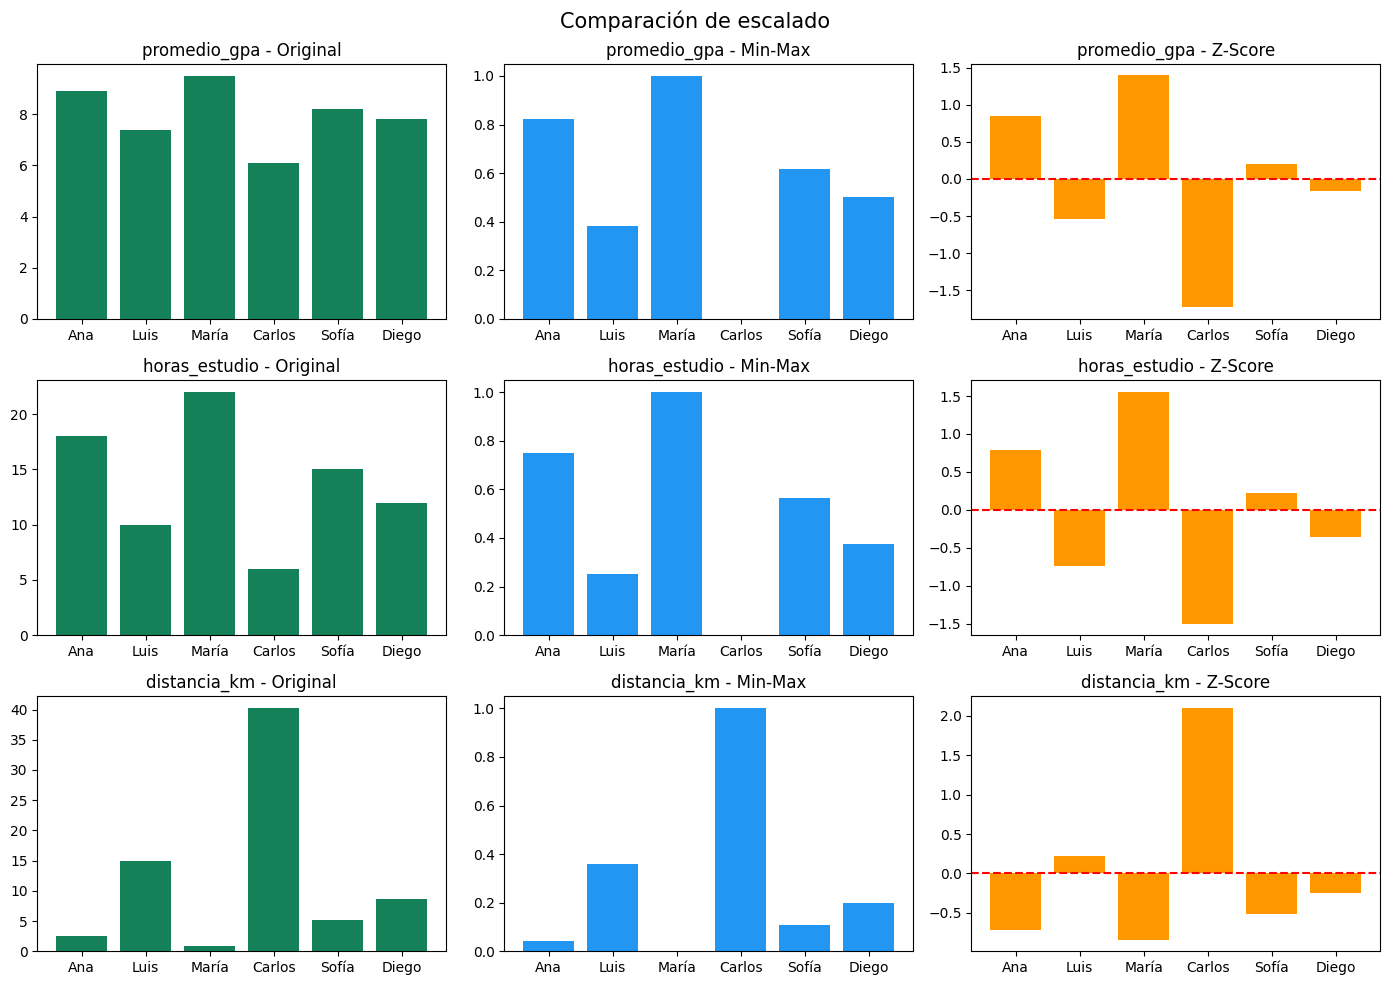

In [44]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
nombres = df["nombre"].values

for i, col in enumerate(columnas_numericas):
    axes[i, 0].bar(nombres, X[:, i], color="#158158")
    axes[i, 0].set_title(f"{col} - Original")

    axes[i, 1].bar(nombres, X_minmax[:, i], color="#2196F3")
    axes[i, 1].set_title(f"{col} - Min-Max")

    axes[i, 2].bar(nombres, X_zscore[:, i], color="#FF9800")
    axes[i, 2].axhline(0, color="red", linestyle="--")
    axes[i, 2].set_title(f"{col} - Z-Score")

plt.suptitle("Comparación de escalado", fontsize=15)
plt.tight_layout()
plt.savefig("comparacion_escalado.png")
plt.show()



### P14. ¿Se mantienen las proporciones relativas?

Las transformaciones conservan el orden de los estudiantes y las diferencias relativas dentro de cada variable, aunque cambian la escala y el punto de referencia. Min-Max ajusta los datos entre 0 y 1, mientras que Z-Score los centra alrededor de 0.


#Actividad 2.5. Simular un valor extremo

In [45]:

X_con_outlier = np.vstack([X, [8.5, 14, 120.0]])

X_mm_con_outlier, _, _ = min_max_manual(X_con_outlier)
X_z_con_outlier, _, _ = zscore_manual(X_con_outlier)

nombres_ext = list(nombres) + ["Nuevo"]

resultado = pd.DataFrame({
    "Estudiante": nombres_ext,
    "Original": X_con_outlier[:, 2],
    "Min-Max": X_mm_con_outlier[:, 2],
    "Z-Score": X_z_con_outlier[:, 2]
})

display(resultado.round(4))


,Estudiante,Original,Min-Max,Z-Score
0,Ana,2.5,0.0143,-0.6280
1,Luis,15.0,0.1191,-0.3137
2,María,0.8,0.0000,-0.6708
3,Carlos,40.2,0.3305,0.3201
4,Sofía,5.1,0.0361,-0.5626
5,Diego,8.7,0.0663,-0.4721
6,Nuevo,120.0,1.0000,2.3271



### P15. ¿Qué problema genera el outlier?

El valor extremo de 120 km comprime los valores de los demás estudiantes cuando se aplica Min-Max. Z-Score también se ve afectado porque utiliza la media y la desviación estándar. RobustScaler puede ser una mejor alternativa porque utiliza la mediana y el rango intercuartílico, que son menos sensibles a valores extremos.


# FASE 3. Dataset real Palmer Penguins

#Actividad 3.1. Cargar y explorar los datos


In [46]:
url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"

df_penguins = pd.read_csv(url)

print("=== PRIMERA VISTA ===")
display(df_penguins.head(8))

print("Dimensiones:", df_penguins.shape)
print("Columnas:", list(df_penguins.columns))

print("\n=== TIPOS DE DATOS ===")
print(df_penguins.dtypes)

print("\n=== VALORES NULOS ===")
print(df_penguins.isnull().sum())

print("\n=== ESTADÍSTICAS ===")
display(df_penguins.describe())

print("\n=== VALORES CATEGÓRICOS ===")
for col in df_penguins.select_dtypes(include="object").columns:
    print(col, df_penguins[col].unique())


=== PRIMERA VISTA ===


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,female,2007
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,male,2007


Dimensiones: (344, 8)
Columnas: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']

=== TIPOS DE DATOS ===
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64
dtype: object

=== VALORES NULOS ===
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

=== ESTADÍSTICAS ===


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000



=== VALORES CATEGÓRICOS ===
species ['Adelie' 'Gentoo' 'Chinstrap']
island ['Torgersen' 'Biscoe' 'Dream']
sex ['male' 'female' nan]



### P16. ¿Cuántas instancias tiene el dataset?

El dataset contiene 344 instancias. Sus principales features numéricas son bill_length_mm, bill_depth_mm, flipper_length_mm y body_mass_g. El label más lógico para una clasificación es species.

### P17. ¿Existen valores nulos?

Sí, existen valores nulos en algunas columnas. Es importante tratarlos antes del escalado para evitar resultados incompletos o errores en los algoritmos. Algunas funciones pueden conservar los NaN y propagarlos a etapas posteriores.


#Actividad 3.2. Clasificar las variables

In [47]:
tipos_penguins = pd.DataFrame({
    "Columna": [
        "species", "island", "bill_length_mm",
        "bill_depth_mm", "flipper_length_mm",
        "body_mass_g", "sex", "year"
    ],
    "Clasificación": [
        "Cualitativa nominal",
        "Cualitativa nominal",
        "Cuantitativa continua",
        "Cuantitativa continua",
        "Cuantitativa continua",
        "Cuantitativa continua",
        "Cualitativa nominal",
        "Cuantitativa discreta"
    ]
})

display(tipos_penguins)


,Columna,Clasificación
0,species,Cualitativa nominal
1,island,Cualitativa nominal
2,bill_length_mm,Cuantitativa continua
3,bill_depth_mm,Cuantitativa continua
4,flipper_length_mm,Cuantitativa continua
5,body_mass_g,Cuantitativa continua
6,sex,Cualitativa nominal
7,year,Cuantitativa discreta



### P18. ¿sex e island son nominales?

Sí. Ambas son variables cualitativas nominales porque sus categorías no poseen un orden natural. Si las islas se clasificaran según la temperatura del océano, se crearía una nueva variable ordinal, pero el nombre de la isla seguiría siendo nominal.


#Actividad 3.3. Limpiar y seleccionar features

In [48]:
df_clean = df_penguins.dropna()

print("Filas originales:", len(df_penguins))
print("Filas limpias:", len(df_clean))

features_num = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

X_penguins = df_clean[features_num].values

display(
    pd.DataFrame(
        X_penguins,
        columns=features_num
    ).describe().round(2)
)


Filas originales: 344
Filas limpias: 333


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,333.00,333.00,333.00,333.00
mean,43.99,17.16,200.97,4207.06
std,5.47,1.97,14.02,805.22
min,32.10,13.10,172.00,2700.00
25%,39.50,15.60,190.00,3550.00
50%,44.50,17.30,197.00,4050.00
75%,48.60,18.70,213.00,4775.00
max,59.60,21.50,231.00,6300.00



### P19. ¿Qué variable tendrá mayor peso sin escalado?

body_mass_g puede dominar el cálculo de distancias porque sus valores son mucho mayores que los de bill_depth_mm. Esto no significa que sea biológicamente más importante, sino que tiene una escala numérica mayor.


#Actividad 3.4. Aplicar escalado y analizar distribuciones

--- Min-Max ---


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,333.0000,333.0000,333.0000,333.0000
mean,0.4325,0.4839,0.4910,0.4186
std,0.1989,0.2344,0.2376,0.2237
min,0.0000,0.0000,0.0000,0.0000
25%,0.2691,0.2976,0.3051,0.2361
50%,0.4509,0.5000,0.4237,0.3750
75%,0.6000,0.6667,0.6949,0.5764
max,1.0000,1.0000,1.0000,1.0000


--- Z-Score ---


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,333.0000,333.0000,333.0000,333.0000
mean,-0.0000,-0.0000,0.0000,-0.0000
std,1.0015,1.0015,1.0015,1.0015
min,-2.1780,-2.0673,-2.0699,-1.8744
25%,-0.8228,-0.7959,-0.7837,-0.8172
50%,0.0929,0.0687,-0.2835,-0.1953
75%,0.8437,0.7807,0.8598,0.7064
max,2.8582,2.2047,2.1460,2.6031


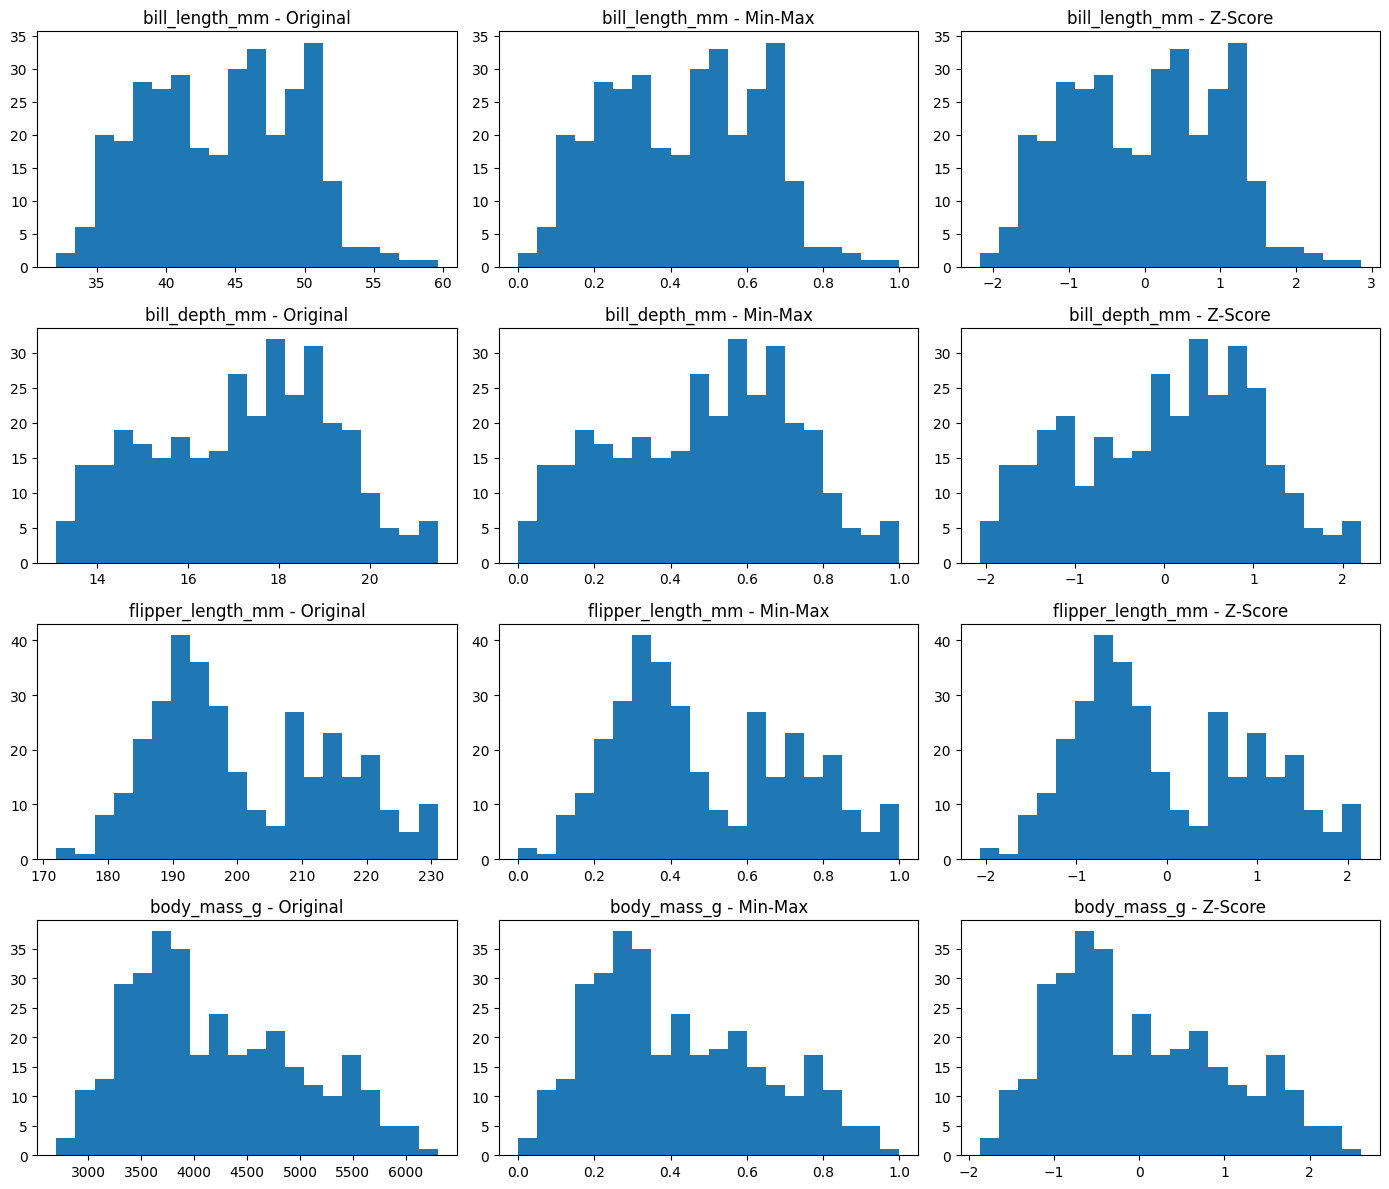

In [31]:
mm = MinMaxScaler()
X_mm = mm.fit_transform(X_penguins)

zs = StandardScaler()
X_zs = zs.fit_transform(X_penguins)

print("--- Min-Max ---")
display(pd.DataFrame(X_mm, columns=features_num).describe().round(4))

print("--- Z-Score ---")
display(pd.DataFrame(X_zs, columns=features_num).describe().round(4))

fig, axes = plt.subplots(4, 3, figsize=(14, 12))

for i, col in enumerate(features_num):
    axes[i, 0].hist(X_penguins[:, i], bins=20)
    axes[i, 0].set_title(f"{col} - Original")

    axes[i, 1].hist(X_mm[:, i], bins=20)
    axes[i, 1].set_title(f"{col} - Min-Max")

    axes[i, 2].hist(X_zs[:, i], bins=20)
    axes[i, 2].set_title(f"{col} - Z-Score")

plt.tight_layout()
plt.show()



### P20. ¿El escalado cambia la forma de la distribución?

No. Min-Max y Z-Score son transformaciones lineales que conservan la forma de la distribución. Cambian la escala del eje horizontal, pero no convierten una distribución asimétrica en normal.

### P21. ¿body_mass_g presenta una distribución normal?

La distribución de body_mass_g puede presentar agrupamientos y desviaciones respecto a una campana normal, debido a las diferencias entre especies. Z-Score no requiere normalidad para aplicarse, aunque su interpretación resulta más sencilla en distribuciones aproximadamente normales.


# FASE 4. Comparación de escaladores con Scikit-learn

#Actividad 4.1. Preparar nuevamente el dataset

In [32]:
from sklearn.model_selection import train_test_split

X = df_clean[features_num].values

print("Dataset listo:", X.shape)

display(pd.DataFrame(X, columns=features_num).describe().round(2))


Dataset listo: (333, 4)


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,333.00,333.00,333.00,333.00
mean,43.99,17.16,200.97,4207.06
std,5.47,1.97,14.02,805.22
min,32.10,13.10,172.00,2700.00
25%,39.50,15.60,190.00,3550.00
50%,44.50,17.30,197.00,4050.00
75%,48.60,18.70,213.00,4775.00
max,59.60,21.50,231.00,6300.00


In [33]:
rangos = X.max(axis=0) - X.min(axis=0)

df_rangos = pd.DataFrame({
    "Feature": features_num,
    "Rango": rangos
})

display(df_rangos)

print("Mayor rango:", features_num[np.argmax(rangos)])
print("Menor rango:", features_num[np.argmin(rangos)])


,Feature,Rango
0,bill_length_mm,27.5
1,bill_depth_mm,8.4
2,flipper_length_mm,59.0
3,body_mass_g,3600.0


Mayor rango: body_mass_g
Menor rango: bill_depth_mm


#Actividad 4.2. Dividir entrenamiento y prueba

In [34]:
X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)


Train: (266, 4)
Test: (67, 4)



### P23. ¿Por qué se divide antes de escalar?

Porque el escalador debe aprender sus parámetros únicamente de los datos de entrenamiento. Si se escala todo el dataset antes de dividirlo, se utiliza información del conjunto de prueba durante el entrenamiento. Esto se conoce como data leakage y puede producir evaluaciones demasiado optimistas.


#Actividad 4.3. Aplicar los tres escaladores

In [35]:
mm_scaler = MinMaxScaler()
zs_scaler = StandardScaler()
rb_scaler = RobustScaler()

X_train_mm = mm_scaler.fit_transform(X_train)
X_train_zs = zs_scaler.fit_transform(X_train)
X_train_rb = rb_scaler.fit_transform(X_train)

X_test_mm = mm_scaler.transform(X_test)
X_test_zs = zs_scaler.transform(X_test)
X_test_rb = rb_scaler.transform(X_test)

print("=== MIN-MAX ===")
print("Mínimos:", mm_scaler.data_min_.round(2))
print("Máximos:", mm_scaler.data_max_.round(2))

print("\n=== Z-SCORE ===")
print("Medias:", zs_scaler.mean_.round(2))
print("Desviaciones:", zs_scaler.scale_.round(2))

print("\n=== ROBUST SCALER ===")
print("Medianas:", rb_scaler.center_.round(2))
print("IQR:", rb_scaler.scale_.round(2))


=== MIN-MAX ===
Mínimos: [  32.1   13.1  172.  2700. ]
Máximos: [  59.6   21.5  231.  6050. ]

=== Z-SCORE ===
Medias: [  44.08   17.07  201.41 4232.61]
Desviaciones: [  5.41   1.97  14.24 809.57]

=== ROBUST SCALER ===
Medianas: [  44.9   17.2  197.  4100. ]
IQR: [   8.9    3.2   24.  1200. ]


In [36]:
masa_train = X_train[:, 3]

mediana = np.median(masa_train)
q1 = np.percentile(masa_train, 25)
q3 = np.percentile(masa_train, 75)
iqr = q3 - q1

print("Mediana manual:", mediana)
print("Mediana RobustScaler:", rb_scaler.center_[3])

print("IQR manual:", iqr)
print("IQR RobustScaler:", rb_scaler.scale_[3])

print("¿Coinciden las medianas?",
      np.isclose(mediana, rb_scaler.center_[3]))

print("¿Coinciden los IQR?",
      np.isclose(iqr, rb_scaler.scale_[3]))


Mediana manual: 4100.0
Mediana RobustScaler: 4100.0
IQR manual: 1200.0
IQR RobustScaler: 1200.0
¿Coinciden las medianas? True
¿Coinciden los IQR? True



### Comparación de los parámetros

Los parámetros de MinMaxScaler aplicado a Palmer Penguins no son iguales a los calculados manualmente en la Fase 2, porque se utilizan datasets diferentes. Además, en esta fase el escalador aprende únicamente del conjunto de entrenamiento.

### Verificación de RobustScaler

La mediana y el rango intercuartílico calculados manualmente para body_mass_g coinciden con los parámetros aprendidos por RobustScaler, siempre que se utilicen los mismos datos de entrenamiento.



# CONCLUSIONES

1. En esta práctica aprendí a identificar las instancias, atributos, features y labels de un dataset. También comprendí cómo clasificar las variables según sus características y su importancia en el análisis de datos.

2. Logré aplicar las técnicas de escalado Min-Max y Z-Score utilizando NumPy. Mediante los resultados y las gráficas, pude observar cómo cambian las escalas de los datos y comprendí las diferencias entre ambas técnicas.

3. Al trabajar con valores extremos, pude comprobar que Min-Max es sensible a los datos atípicos. Esto me ayudó a entender por qué es importante seleccionar una técnica de escalado adecuada según las características del dataset.

4. Aprendí a utilizar Pandas y Scikit-learn para limpiar, analizar y transformar datos reales. Además, comprendí que RobustScaler puede ser una mejor opción cuando existen valores extremos.

5. Finalmente, considero que esta práctica me permitió fortalecer mis conocimientos sobre el preprocesamiento de datos en inteligencia artificial. Comprendí la importancia de preparar correctamente la información antes de utilizarla en un modelo de aprendizaje automático.
